# 02 · Merge into 3 datasets, clean, and preprocess for the model

**Step 1 – Merge** the 11 structured CSVs into 3 datasets and save them (raw, not cleaned yet) to `structured_csv/merged/`:

| File | One row = | Built from |
|---|---|---|
| `static_merged.csv` | one hospital admission | patients + admissions + diagnoses (patient history / medical record) |
| `clinical_merged.csv` | one clinical measurement or report | labs + ECG recordings + medications + events (long format) |
| `dynamic_merged.csv` | one ICU hour | vitals_hourly + rhythm (real-time stream) |

**Step 2 – Reload** those 3 CSVs, **clean** them, and save `static_clean.csv`, `clinical_clean.csv`, `dynamic_clean.csv` to `structured_csv/cleaned/`.

**Step 3 – Build** `model_table.csv` (one row per ICU hour with everything joined + the label) and save the charts to `structured_csv/cleaned/figures/`.

**Step 4 – Clean** the two extra datasets from different patients (wearable, I-CARE).

**Step 5 – Preprocess for the model:** more features, patient-based train/test split, feature selection, scaling, class weights, and a reusable pipeline file for the live twin. Output: `model_ready.csv`, `model_ready_scaled.csv`, `preprocess_config.json` and `twin_preprocess.py`.

Your original 11 CSVs are only read, never changed. Every file is saved as `.csv` and `.pkl` (the PKL keeps dates and dtypes).

This notebook has **already been run**: every output is saved under its cell. Each code cell has a **What this cell does** note above it and a **Result** note below it. To re-run it, open it from the `Happiest_Health` folder and choose **Run → Run All Cells** (under a minute; needs only pandas, numpy and matplotlib).

## 0 · Setup

**What this cell does:** imports pandas, numpy and matplotlib, finds the `structured_csv` folder (relative to this notebook in `Happiest_Health`), creates `structured_csv/merged/`, `structured_csv/cleaned/` and `cleaned/figures/`, and defines `save()` (writes every table as `.csv` and `.pkl`) and `savefig()` (writes every chart as `.png`).

In [1]:
import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore", category=DeprecationWarning)

# the notebook sits in notebooks/, so the data is in ../data
DATA = Path("../data") if Path("../data").exists() else Path("data")
MERGED, CLEAN = DATA / "merged", DATA / "cleaned"
FIG = CLEAN / "figures"
for d in (MERGED, CLEAN, FIG):
    d.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_columns", 60)
report = {}

def save(df, folder, name):
    df.to_csv(folder / f"{name}.csv", index=False)
    df.to_pickle(folder / f"{name}.pkl")
    report.setdefault("saved", {})[f"{folder.name}/{name}"] = list(df.shape)
    print(f"saved {folder.name}/{name:<18} {df.shape[0]:>7,} rows x {df.shape[1]} cols")

def savefig(name):
    plt.tight_layout(); plt.savefig(FIG / f"{name}.png", dpi=130); plt.show()

**Result:** output folders created. Nothing is printed here.

# STEP 1 · Merge the 11 files into 3

**What this cell does:** loads the 11 original CSVs. Time columns are parsed as real dates (**type casting**). The originals are only read, never overwritten.

In [2]:
DATES = {"patients": ["dod"], "admissions": ["admittime", "dischtime", "deathtime"], "diagnoses": [],
         "labs": ["charttime"], "meds": ["starttime", "stoptime"], "vitals_hourly": ["hour"],
         "rhythm": ["charttime"], "ecg": ["ecg_time"], "events": ["event_time"],
         "wearable_5min": ["time"], "icare_patients": []}
raw = {n: pd.read_csv(DATA / f"{n}.csv", parse_dates=d, low_memory=False) for n, d in DATES.items()}
pd.DataFrame({n: d.shape for n, d in raw.items()}, index=["rows", "cols"]).T

,rows,cols
patients,100,26
admissions,275,26
diagnoses,4506,6
labs,34587,9
meds,2856,9
vitals_hourly,12101,14
rhythm,12460,5
ecg,659,27
events,288,4
wearable_5min,895,22


**Result:** 11 tables loaded: patients 100×26, admissions 275×26, diagnoses 4,506×6, labs 34,587×9, meds 2,856×9, vitals_hourly 12,101×14, rhythm 12,460×5, ecg 659×27, events 288×4, wearable_5min 895×22, icare_patients 166×11.

**What this cell does (merge 1: STATIC, the patient history / medical record):** joins `admissions` + `patients` (on `subject_id`) + a per-admission summary of `diagnoses` (number of codes, primary diagnosis, the full code list). The admission's condition flags are renamed `dx_*`. No cleaning yet.

In [3]:
# 1a. STATIC = admissions + patients + diagnoses (one row per admission)
COND = ["hf", "af", "cad", "mi", "arrest", "htn", "dm", "ckd", "stroke", "sepsis"]
dx = raw["diagnoses"]
dx_sum = (dx.sort_values("seq_num").groupby("hadm_id")
            .agg(n_diagnoses=("icd_code", "size"), primary_dx_code=("icd_code", "first"),
                 primary_dx_title=("long_title", "first"),
                 all_dx_codes=("icd_code", lambda s: ";".join(s.astype(str)))).reset_index())
# real history items coded in each admission (ICD-9 and ICD-10 codes, no made-up data)
HX_CODES = {
    "smoker":             r"^(3051|V1582|F17|Z87891|Z720)",        # current or past tobacco use
    "fam_hx_cad":         r"^(V173|V174|Z8249|Z824)",              # family history of ischemic heart disease
    "hyperlipidemia":     r"^(2720|2721|2722|2724|E78)",
    "obesity":            r"^(2780|E66)",
    "prior_mi_or_revasc": r"^(412|V4581|V4582|Z951|Z955|I252)",    # old MI, stent, bypass
}
code = dx.icd_code.astype(str).str.strip()
hx_flags = pd.DataFrame({f"code_{k}": code.str.match(p).astype(int) for k, p in HX_CODES.items()})
hx_flags["hadm_id"] = dx.hadm_id
hx_flags = hx_flags.groupby("hadm_id").max().reset_index()

static_merged = (raw["admissions"].rename(columns={c: f"dx_{c}" for c in COND})
                 .merge(raw["patients"], on="subject_id", how="left")
                 .merge(dx_sum, on="hadm_id", how="left")
                 .merge(hx_flags, on="hadm_id", how="left")
                 .sort_values(["subject_id", "admittime"]).reset_index(drop=True))
save(static_merged, MERGED, "static_merged")
static_merged.head(3)

saved merged/static_merged          275 rows x 60 cols


,subject_id,hadm_id,admittime,dischtime,deathtime,age_at_admit,admission_type,admission_location,discharge_location,insurance,race,los_days,icu_stays,icu_los_days,dx_hf,dx_af,dx_cad,dx_mi,dx_arrest,dx_htn,dx_dm,dx_ckd,dx_stroke,dx_sepsis,hospital_expire_flag,readmit_30d,gender,anchor_age,anchor_year,anchor_year_group,dod,bmi,height_in,weight_lbs,sbp_outpatient,dbp_outpatient,n_admissions,ever_hf,ever_af,ever_cad,ever_mi,ever_arrest,ever_htn,ever_dm,ever_ckd,ever_stroke,ever_sepsis,n_icu_stays,died,has_ecg,has_wearable,n_diagnoses,primary_dx_code,primary_dx_title,all_dx_codes,code_smoker,code_fam_hx_cad,code_hyperlipidemia,code_obesity,code_prior_mi_or_revasc
0,10000032,22595853,2180-05-06 22:23:00,2180-05-07 17:15:00,NaT,52,URGENT,TRANSFER FROM HOSPITAL,HOME,Other,WHITE,0.79,0,NaN,0,0,0,0,0,0,0,0,0,0,0,0,F,52,2180,2014 - 2016,2180-09-09,18.2,60.0,93.03,98.0,66.0,4,0,0,0,0,0,0,0,0,0,0,1,1,1,0,8,5723,Portal hypertension,5723;78959;5715;07070;496;29680;30981;V1582,1,0,0,0,0
1,10000032,22841357,2180-06-26 18:27:00,2180-06-27 18:49:00,NaT,52,EW EMER.,EMERGENCY ROOM,HOME,Medicaid,WHITE,1.02,0,NaN,0,0,0,0,0,0,0,0,0,0,0,1,F,52,2180,2014 - 2016,2180-09-09,18.2,60.0,93.03,98.0,66.0,4,0,0,0,0,0,0,0,0,0,0,1,1,1,0,8,07071,Unspecified viral hepatitis C with hepatic coma,07071;78959;2875;2761;496;5715;V08;3051,1,0,0,0,0
2,10000032,29079034,2180-07-23 12:35:00,2180-07-25 17:55:00,NaT,52,EW EMER.,EMERGENCY ROOM,HOME,Medicaid,WHITE,2.22,1,0.410266,0,0,0,0,0,0,0,0,0,0,0,1,F,52,2180,2014 - 2016,2180-09-09,18.2,60.0,93.03,98.0,66.0,4,0,0,0,0,0,0,0,0,0,0,1,1,1,0,13,45829,Other iatrogenic hypotension,45829;07044;7994;2761;78959;2767;3051;V08;V498...,1,0,0,0,0


**Result:** `merged/static_merged.csv` saved: **275 admissions × 55 columns** for the 100 patients.

**What this cell does (merge 2: CLINICAL, measurements and reports):** stacks four sources into one **long** table with the same columns (`subject_id, hadm_id, time, source, item, value, unit, detail`):
- `lab`: every blood test (LDL, troponin, potassium…)
- `ecg`: each 12-lead ECG recording's features (heart rate, HRV…), one row per feature
- `med`: each cardiac drug order (value 1, with `stoptime` and the dose in `detail`)
- `event`: each adverse event (vasopressor start, death…)

In [4]:
# 1b. CLINICAL = labs + ECG + meds + events, stacked in one long table
#     common columns: subject_id, hadm_id, time, source, item, value, unit, detail
labs = raw["labs"].assign(source="lab").rename(columns={"charttime": "time", "lab": "item"})
labs["detail"] = labs.flag
labs = labs[["subject_id", "hadm_id", "time", "source", "item", "value", "unit", "ref_range_lower", "ref_range_upper", "detail"]]

ECG_COLS = [c for c in raw["ecg"].columns if c not in ("subject_id", "study_id", "hadm_id", "ecg_time", "lead_used")]
ecg = (raw["ecg"].melt(id_vars=["subject_id", "study_id", "hadm_id", "ecg_time"], value_vars=ECG_COLS,
                       var_name="item", value_name="value")
          .rename(columns={"ecg_time": "time"}).assign(source="ecg"))
ecg["unit"] = ecg.item.str.extract(r"_(ms|mv|bpm)$", expand=False)
ecg["detail"] = "study " + ecg.study_id.astype(str)

meds = raw["meds"].assign(source="med", value=1.0).rename(columns={"starttime": "time", "drug_class": "item"})
meds["detail"] = meds.drug + " " + meds.dose_val_rx.astype(str) + " " + meds.dose_unit_rx.astype(str) + " " + meds.route
meds["unit"] = "order"

events = raw["events"].assign(source="event", value=1.0, unit="event").rename(columns={"event_time": "time", "event": "item"})

clinical_merged = (pd.concat([labs, ecg.drop(columns="study_id"), meds[["subject_id", "hadm_id", "time", "stoptime", "source", "item", "value", "unit", "detail"]], events],
                             ignore_index=True)
                   .sort_values(["subject_id", "time", "source", "item"]).reset_index(drop=True))
clinical_merged["hadm_id"] = clinical_merged.hadm_id.astype("Int64")
save(clinical_merged, MERGED, "clinical_merged")
print(clinical_merged.source.value_counts().to_dict())
clinical_merged.head(5)

saved merged/clinical_merged     52,229 rows x 11 cols
{'lab': 34587, 'ecg': 14498, 'med': 2856, 'event': 288}


,subject_id,hadm_id,time,source,item,value,unit,ref_range_lower,ref_range_upper,detail,stoptime
0,10000032,<NA>,2180-03-23 11:51:00,lab,albumin,3.3,g/dL,3.5,5.2,abnormal,NaT
1,10000032,<NA>,2180-03-23 11:51:00,lab,bicarbonate,27.0,mEq/L,22.0,32.0,NaN,NaT
2,10000032,<NA>,2180-03-23 11:51:00,lab,bun,13.0,mg/dL,6.0,20.0,NaN,NaT
3,10000032,<NA>,2180-03-23 11:51:00,lab,calcium,8.4,mg/dL,8.4,10.3,NaN,NaT
4,10000032,<NA>,2180-03-23 11:51:00,lab,chol_total,202.0,mg/dL,0.0,199.0,abnormal,NaT


**Result:** `merged/clinical_merged.csv` saved: **52,229 rows × 11 columns**: 34,587 lab, 14,498 ECG, 2,856 med and 288 event rows.

**What this cell does (merge 3: DYNAMIC, the real-time stream):** takes the hourly ICU vitals (HR, SpO2, RR, BP, temperature, GCS) and attaches the nurse-charted heart rhythm from the last 4 hours (`merge_asof`).

In [5]:
# 1c. DYNAMIC = hourly ICU vitals + the latest charted heart rhythm (within 4 h)
rh = raw["rhythm"][["stay_id", "charttime", "rhythm"]].rename(columns={"charttime": "hour"}).sort_values("hour")
dynamic_merged = pd.merge_asof(raw["vitals_hourly"].sort_values("hour"), rh, on="hour", by="stay_id",
                               direction="backward", tolerance=pd.Timedelta(hours=4))
dynamic_merged = dynamic_merged.sort_values(["subject_id", "stay_id", "hour"]).reset_index(drop=True)
save(dynamic_merged, MERGED, "dynamic_merged")
dynamic_merged.head(3)

saved merged/dynamic_merged      12,101 rows x 15 cols


,subject_id,hadm_id,stay_id,hour,hours_since_icu_admit,hr,spo2,rr,sbp,dbp,map,bp_source,temp_c,gcs_total,rhythm
0,10000032,29079034,39553978,2180-07-23 14:00:00,0.0,92.0,97.5,22.5,89.5,53.5,61.5,cuff,37.1,14.0,SR (Sinus Rhythm)
1,10000032,29079034,39553978,2180-07-23 15:00:00,1.0,94.0,97.0,23.0,88.0,56.0,64.0,cuff,NaN,NaN,SR (Sinus Rhythm)
2,10000032,29079034,39553978,2180-07-23 16:00:00,2.0,105.0,94.0,21.0,91.0,55.0,64.0,cuff,NaN,NaN,ST (Sinus Tachycardia)


**Result:** `merged/dynamic_merged.csv` saved: **12,101 ICU hours × 15 columns** (140 ICU stays). You can already see the raw problems in the first rows: temperature and GCS are blank in most hours.

# STEP 2 · Reload the 3 merged CSVs and clean them

**What this cell does:** **reloads the 3 merged CSVs from disk** (so the cleaning works on exactly what was saved), checks for **duplicate rows**, and charts the **% missing per column** before cleaning.

static    (275, 60)  duplicates: 0
clinical  (52229, 11)  duplicates: 36
dynamic   (12101, 15)  duplicates: 0


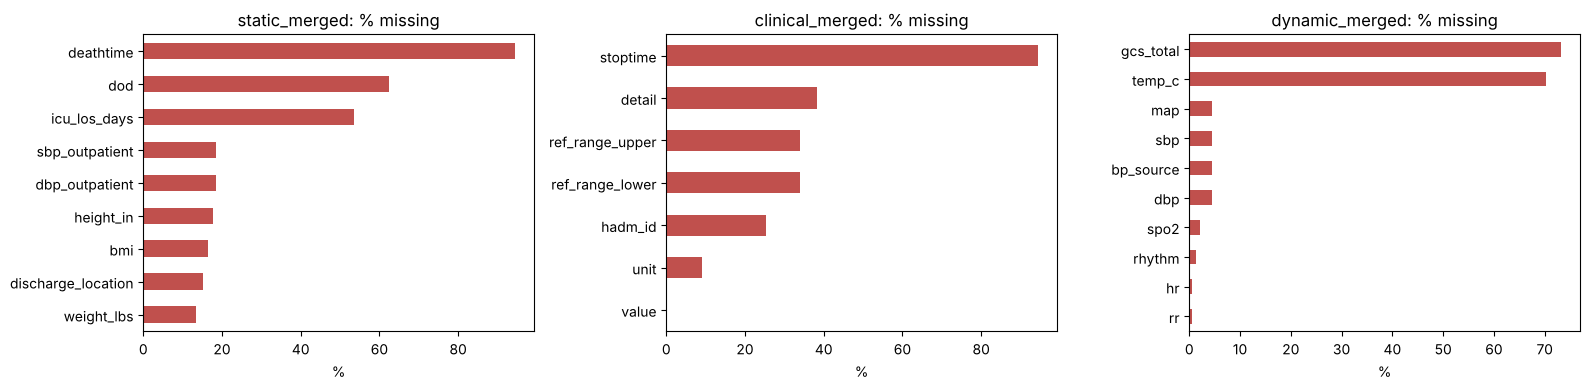

In [6]:
static = pd.read_csv(MERGED / "static_merged.csv", parse_dates=["admittime", "dischtime", "deathtime", "dod"])
clinical = pd.read_csv(MERGED / "clinical_merged.csv", parse_dates=["time", "stoptime"], low_memory=False)
dynamic = pd.read_csv(MERGED / "dynamic_merged.csv", parse_dates=["hour"])
clinical["hadm_id"] = clinical.hadm_id.astype("Int64")
for name, df in [("static", static), ("clinical", clinical), ("dynamic", dynamic)]:
    print(f"{name:<9} {df.shape}  duplicates: {df.duplicated().sum()}")

# % missing before cleaning
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, (name, df) in zip(axes, [("static", static), ("clinical", clinical), ("dynamic", dynamic)]):
    m = df.isna().mean().mul(100).sort_values()
    m[m > 0].plot.barh(ax=ax, color="#c0504d"); ax.set_title(f"{name}_merged: % missing"); ax.set_xlabel("%")
savefig("01_missing_before")

**Result:** static 275×60, clinical 52,229×11 (36 exact duplicate rows: 18 med and 18 lab), dynamic 12,101×15. Chart saved as `figures/01_missing_before.png`. The biggest gaps are GCS (73%) and temperature (70%) in dynamic, BMI/height (~38%) and the death/ICU columns (blank means *no*) in static.

**What this cell does (cleaning STATIC):**
1. **History features** from earlier admissions only (`hist_*`, `prior_admissions`, `days_since_last_discharge`), so there's no leakage from the current stay's discharge codes.
   Plus **risk-factor history from real ICD codes**: `smoker`, `hyperlipidemia`, `obesity`, `prior_mi_or_revasc`, `fam_hx_cad` (family history of heart disease) and `cad_history`, each counted if coded in this or any earlier admission.
2. **Leakage removal:** outcomes get a `y_` prefix, and `discharge_location` (contains "DIED") and lifetime counts are dropped.
3. **Semantic nulls:** a blank `icu_los_days` means 0, and a blank `days_since_last_discharge` means first admission (-1).
4. **Category standardisation:** race grouped from 14 labels into 5, and admission type from 9 into 4. Gender is encoded as 0/1.
5. **Plausibility check + median imputation by gender + `_missing` flags** for BMI, height, weight and outpatient BP.
6. **Log transform** of prior admissions.

In [7]:
# 2a. CLEAN STATIC
s = static.copy()
# history from EARLIER admissions only (no leakage)
for c in COND:
    s[f"hist_{c}"] = s.groupby("subject_id")[f"dx_{c}"].transform(lambda x: x.shift().fillna(0).cummax()).astype(int)
# risk-factor history: coded in THIS or any EARLIER admission (chronic traits such as smoking or family history)
for k in HX_CODES:
    s[k] = s.groupby("subject_id")[f"code_{k}"].transform(lambda x: x.fillna(0).cummax()).astype(int)
# CAD history = CAD coded now or before, or an old MI / stent / bypass
s["cad_history"] = (s.groupby("subject_id").dx_cad.transform("cummax") | s.prior_mi_or_revasc).astype(int)
s = s.drop(columns=[f"code_{k}" for k in HX_CODES])
s["prior_admissions"] = s.groupby("subject_id").cumcount()
s["days_since_last_discharge"] = ((s.admittime - s.groupby("subject_id").dischtime.shift()).dt.total_seconds() / 86400).fillna(-1)
# outcomes -> y_ prefix; drop leaking / lifetime / redundant columns
s = s.rename(columns={"hospital_expire_flag": "y_died_in_hospital", "readmit_30d": "y_readmit_30d",
                      "los_days": "y_los_days", "died": "y_died_ever"})
s = s.drop(columns=["discharge_location", "deathtime", "dod", "anchor_year", "anchor_year_group", "has_wearable",
                    "all_dx_codes"] + [f"ever_{c}" for c in COND])
# blanks that mean 0
s["icu_los_days"] = s.icu_los_days.fillna(0)
# categories
s["race"] = (s.race.str.upper().str.strip()
               .replace({r"^WHITE.*": "WHITE", r"^BLACK.*": "BLACK", r"^HISPANIC.*": "HISPANIC", r"^ASIAN.*": "ASIAN"}, regex=True))
s.loc[~s.race.isin(["WHITE", "BLACK", "HISPANIC", "ASIAN"]), "race"] = "OTHER/UNKNOWN"
s["admission_type"] = s.admission_type.str.strip().map(
    lambda t: "emergency" if "EMER" in t else "observation" if "OBSERVATION" in t else "urgent" if t == "URGENT" else "elective/surgical")
s["gender_male"] = (s.gender == "M").astype(int)
# plausibility + median imputation by gender + missing flags
s.loc[~s.bmi.between(12, 70), "bmi"] = np.nan
report["static_imputed"] = {}
for c in ["bmi", "height_in", "weight_lbs", "sbp_outpatient", "dbp_outpatient"]:
    s[f"{c}_missing"] = s[c].isna().astype(int)
    report["static_imputed"][c] = int(s[c].isna().sum())
    s[c] = s[c].fillna(s.groupby("gender")[c].transform("median")).fillna(s[c].median())
s["log_prior_admissions"] = np.log1p(s.prior_admissions)
static_clean = s
save(static_clean, CLEAN, "static_clean")
print("imputed:", report["static_imputed"])
report["risk_factor_patients"] = {k: int(s.groupby("subject_id")[k].max().sum()) for k in list(HX_CODES) + ["cad_history"]}
print("patients with each risk factor:", report["risk_factor_patients"])

saved cleaned/static_clean           275 rows x 63 cols
imputed: {'bmi': 45, 'height_in': 49, 'weight_lbs': 37, 'sbp_outpatient': 51, 'dbp_outpatient': 51}
patients with each risk factor: {'smoker': 48, 'fam_hx_cad': 8, 'hyperlipidemia': 51, 'obesity': 20, 'prior_mi_or_revasc': 16, 'cad_history': 41}


**Result:** `cleaned/static_clean.csv` saved: **275 × 63**. Filled values: BMI 45, height 49, weight 37, outpatient SBP/DBP 51 each (all marked in `*_missing`). No missing values are left in the feature columns.

**Real risk-factor history from ICD codes** (patients out of 100): smoker 48, hyperlipidemia 51, obesity 20, prior MI / stent / bypass 16, **CAD history 41**, **family history of CAD 8**. These are real codes from the patients' records, not made-up values.

**What this cell does (cleaning CLINICAL):**
1. **Duplicate removal.**
2. **Text cleanup** of item names.
3. **ECG quality filter:** drops recordings with fewer than 4 detected beats, and sets flat leads (RMS = 0) to NaN.
4. **Lab flags:** `abnormal`/blank becomes 1/0 (blank means normal, not missing). Negative results are impossible, so they become NaN. Very high values such as NT-proBNP 62,656 are **kept**, because they're real in heart failure.
5. **Log transform** of skewed items (creatinine, lactate, troponin, NT-proBNP, CK, HRV…) into a new `value_log` column.

In [8]:
# 2b. CLEAN CLINICAL (labs, ECG, meds, events in one long table)
c = clinical.copy()
n0 = len(c)
c = c.drop_duplicates()
n_dup = n0 - len(c)
c["item"] = c.item.str.strip()
# ECG: drop studies with < 4 detected beats, flat leads (rms = 0) -> NaN, flag low quality
ecg_rows = c.source == "ecg"
bad_studies = c[ecg_rows & (c.item == "n_beats") & (c.value < 4)].detail.unique()
c = c[~(ecg_rows & c.detail.isin(bad_studies))]
c.loc[(c.source == "ecg") & c.item.str.startswith("rms_") & (c.value == 0), "value"] = np.nan
# labs: abnormal flag as 0/1 (blank means normal, not missing); negative results are impossible
# (very high values such as NT-proBNP 62,656 or CK 16,865 are real in heart failure / muscle injury, so they stay)
labs_m = c.source == "lab"
c.loc[labs_m, "detail"] = (c.loc[labs_m, "detail"] == "abnormal").astype(int).astype(str)
too_big = labs_m & (c.value < 0)
c.loc[too_big, "value"] = np.nan
# log of skewed measurements, in a separate column
SKEWED = ["creatinine", "bun", "wbc", "glucose", "lactate", "inr", "troponin_t", "ntprobnp", "ck", "ck_mb",
          "triglycerides", "sdnn_ms", "rmssd_ms"]
c["value_log"] = np.where(c.item.isin(SKEWED), np.log1p(c.value), np.nan)
c = c.dropna(subset=["time"])
report["clinical"] = {"rows_in": n0, "duplicates_removed": n_dup,
                      "ecg_studies_dropped": len(bad_studies), "negative_lab_values_set_nan": int(too_big.sum())}
clinical_clean = c.reset_index(drop=True)
save(clinical_clean, CLEAN, "clinical_clean")
print(report["clinical"])

saved cleaned/clinical_clean      52,171 rows x 12 cols
{'rows_in': 52229, 'duplicates_removed': 36, 'ecg_studies_dropped': 1, 'negative_lab_values_set_nan': 0}


**Result:** `cleaned/clinical_clean.csv` saved: **52,171 rows × 12 columns** (36 duplicates and 1 ECG with no detectable beats removed; no negative lab values found).

**What this cell does (cleaning DYNAMIC):**
1. Drops the hours charted before the official ICU start.
2. Converts temperatures typed in °F into the °C field.
3. **Outlier removal by medical range:** impossible vitals become NaN (HR 20-250, SpO2 50-100, RR 4-60, SBP 50-250, DBP 20-150, MAP 30-200, temp 30-43 °C, GCS 3-15).
4. **Forward-fill imputation (LOCF)** inside each ICU stay (4 h for HR/BP/SpO2/RR, 8 h for temp/GCS), with `*_measured` flags.
5. Rhythm text is grouped into 6 types and **one-hot encoded**. The arterial line becomes a 0/1 flag.
6. **Clinical scores:** `shock_index` = HR / SBP (above 1.0 suggests shock) and `news_score` (NEWS2 early-warning score from RR, SpO2, SBP, HR, temperature and consciousness; 7 or more is high risk).

In [9]:
# 2c. CLEAN DYNAMIC (hourly vitals + rhythm)
v = dynamic.copy()
report["dynamic"] = {"pre_icu_hours_dropped": int((v.hours_since_icu_admit < 0).sum())}
v = v[v.hours_since_icu_admit >= 0].copy()
f_typed = v.temp_c.between(86, 110)                      # Fahrenheit typed into the Celsius field
v.loc[f_typed, "temp_c"] = (v.loc[f_typed, "temp_c"] - 32) * 5 / 9
report["dynamic"]["temp_fahrenheit_fixed"] = int(f_typed.sum())
RANGES = {"hr": (20, 250), "spo2": (50, 100), "rr": (4, 60), "sbp": (50, 250),
          "dbp": (20, 150), "map": (30, 200), "temp_c": (30, 43), "gcs_total": (3, 15)}
before = v[list(RANGES)].copy()
report["dynamic"]["impossible_set_nan"] = {}
for col, (lo, hi) in RANGES.items():
    bad = v[col].notna() & ~v[col].between(lo, hi)
    report["dynamic"]["impossible_set_nan"][col] = int(bad.sum())
    v.loc[bad, col] = np.nan
# forward-fill inside each ICU stay, with limits, + "measured" flags
v = v.sort_values(["stay_id", "hour"])
for col, lim in {"hr": 4, "spo2": 4, "rr": 4, "sbp": 4, "dbp": 4, "map": 4, "temp_c": 8, "gcs_total": 8}.items():
    v[f"{col}_measured"] = v[col].notna().astype(int)
    v[col] = v.groupby("stay_id")[col].ffill(limit=lim)
v["arterial_line"] = (v.groupby("stay_id").bp_source.ffill() == "arterial").astype(int)
# clinical scores computed from the cleaned vitals
v["shock_index"] = (v.hr / v.sbp).round(3)                 # > 1.0 suggests shock
def band(x, cuts, pts):
    return np.select([x <= c for c in cuts], pts[:-1], pts[-1]).astype(float)
news = pd.DataFrame({
    "rr":   band(v.rr, [8, 11, 20, 24], [3, 1, 0, 2, 3]),
    "spo2": band(v.spo2, [91, 93, 95], [3, 2, 1, 0]),
    "sbp":  np.where(v.sbp >= 220, 3, band(v.sbp, [90, 100, 110], [3, 2, 1, 0])),
    "hr":   band(v.hr, [40, 50, 90, 110, 130], [3, 1, 0, 1, 2, 3]),
    "temp": band(v.temp_c, [35, 36, 38, 39], [3, 1, 0, 1, 2]),
    "gcs":  np.where(v.gcs_total < 15, 3, 0),
}, index=v.index)
for col, src in [("rr", "rr"), ("spo2", "spo2"), ("sbp", "sbp"), ("hr", "hr"), ("temp", "temp_c"), ("gcs", "gcs_total")]:
    news.loc[v[src].isna(), col] = 0                       # missing vital adds 0 points
v["news_score"] = news.sum(axis=1).astype(int)             # NEWS2 without the oxygen-therapy item; >= 7 = high risk
# rhythm text -> 6 groups -> one-hot
def rhythm_group(r):
    if pd.isna(r): return "unknown"
    r = r.strip().lower()
    return ("af_flutter" if r.startswith(("af ", "a flut")) else "paced" if "paced" in r else
            "tachy" if r.startswith(("st ", "svt", "pat", "vt ")) else "brady" if r.startswith(("sb ", "jr ")) else
            "sinus" if r.startswith(("sr ", "sa ", "1st av")) else "other")
v["rhythm_group"] = v.rhythm.map(rhythm_group)
v = pd.concat([v.drop(columns=["rhythm", "bp_source"]), pd.get_dummies(v.rhythm_group, prefix="rhythm", dtype=int)], axis=1)
dynamic_clean = v.sort_values(["subject_id", "stay_id", "hour"]).reset_index(drop=True)
save(dynamic_clean, CLEAN, "dynamic_clean")
print(report["dynamic"])

saved cleaned/dynamic_clean       12,015 rows x 32 cols
{'pre_icu_hours_dropped': 86, 'temp_fahrenheit_fixed': 3, 'impossible_set_nan': {'hr': 1, 'spo2': 2, 'rr': 17, 'sbp': 3, 'dbp': 7, 'map': 41, 'temp_c': 0, 'gcs_total': 0}}


**Result:** `cleaned/dynamic_clean.csv` saved: **12,015 hours × 32 columns** (now including `shock_index` and `news_score`). 86 pre-ICU hours dropped, 3 °F temperatures fixed, and impossible values removed: MAP 41, RR 17, DBP 7, SBP 3, SpO2 2, HR 1. Temperature is now missing in 3.4% of hours (was 70%). NEWS score: median 5, range 0 to 16. Shock index: median 0.78, max 2.94.

**What this cell does:** charts each vital **before (red) vs after (blue)** cleaning, and the % missing left after cleaning.

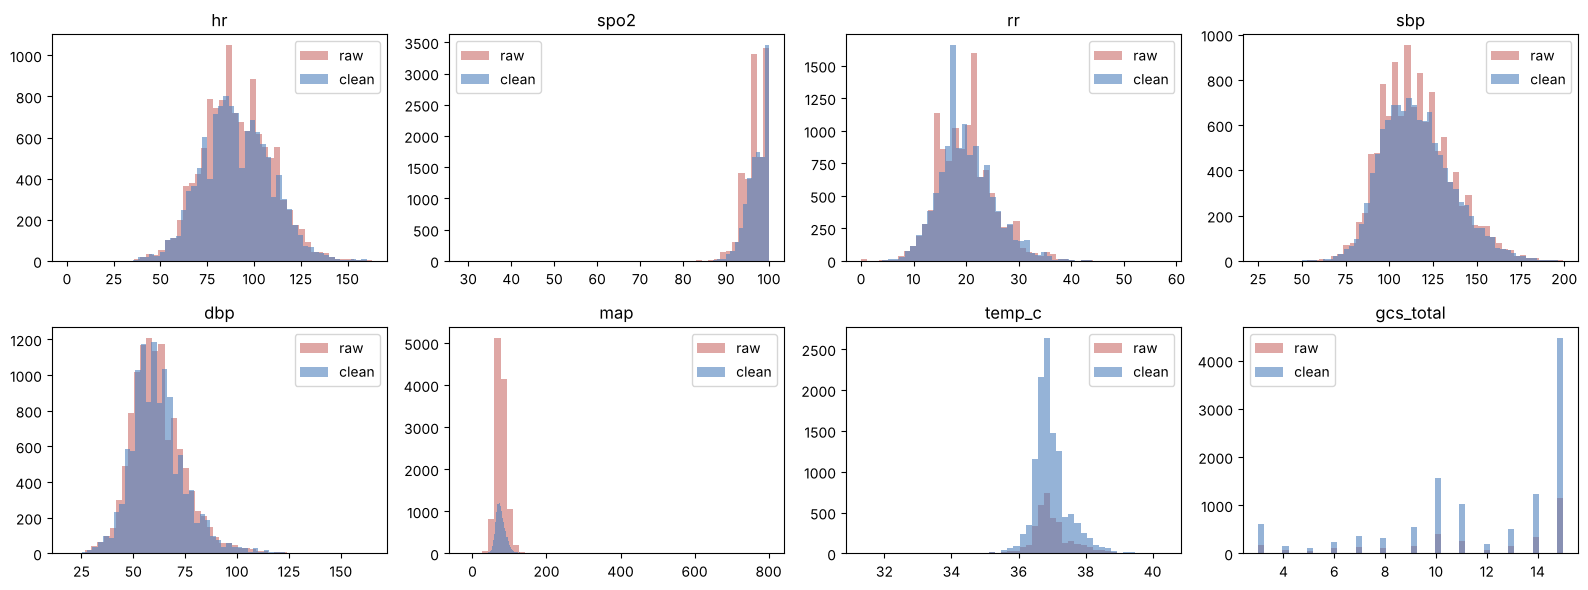

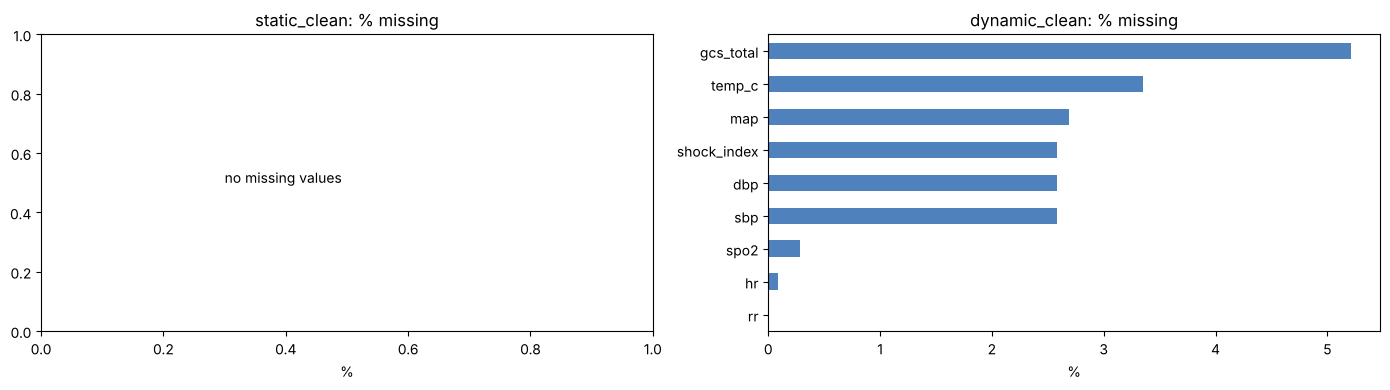

In [10]:
# before / after for the vitals
fig, axes = plt.subplots(2, 4, figsize=(16, 6))
for ax, col in zip(axes.flat, RANGES):
    ax.hist(before[col].dropna(), bins=50, alpha=.5, label="raw", color="#c0504d")
    ax.hist(dynamic_clean[col].dropna(), bins=50, alpha=.6, label="clean", color="#4f81bd")
    ax.set_title(col); ax.legend()
savefig("02_vitals_before_after")

# % missing after cleaning
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, (name, df) in zip(axes, [("static_clean", static_clean), ("dynamic_clean", dynamic_clean)]):
    m = df.isna().mean().mul(100).sort_values()
    m = m[m > 0]
    (m.plot.barh(ax=ax, color="#4f81bd") if len(m) else ax.text(.3, .5, "no missing values"))
    ax.set_title(f"{name}: % missing"); ax.set_xlabel("%")
savefig("03_missing_after")

**Result:** saved `figures/02_vitals_before_after.png` and `figures/03_missing_after.png`. The MAP outliers up to 801 are gone, and the shape of every other vital is unchanged, so only errors were removed, not real signal.

# STEP 3 · Join the 3 clean datasets into the model table (+ label)

**What this cell does (joining the 3 clean datasets):** for every ICU hour in `dynamic_clean`:
- the **latest lab results** from `clinical_clean` (same admission, at most 24 h old, 72 h for rare labs)
- **on/off flags for each drug class** active that hour
- the **latest ECG** features of that patient plus `hours_since_ecg`
- **static features** known at admission from `static_clean` (age, gender, BMI, history, admission type, race → one-hot)
- the **label**: deterioration (vasopressor, lactate ≥ 4 or death) within 6 h / 12 h. Hours after the first event are dropped (**leakage removal**).
- The 6-hour trends are added later, in Step 5

In [11]:
t = dynamic_clean.copy().sort_values("hour")
cl = clinical_clean

# labs: latest value of each lab within the same admission (24 h, 72 h for rare labs); log value for skewed labs
COMMON = ["potassium", "sodium", "creatinine", "bun", "bicarbonate", "platelets", "hemoglobin", "wbc",
          "glucose", "magnesium", "calcium", "inr", "lactate", "albumin"]
RARE = ["troponin_t", "ntprobnp", "ck", "ck_mb"]
lab = cl[(cl.source == "lab") & cl.hadm_id.notna()].copy()
lab["hadm_id"] = lab.hadm_id.astype("int64")
lab["v"] = lab.value_log.fillna(lab.value)
for name in COMMON + RARE:
    col = f"lab_log_{name}" if name in SKEWED else f"lab_{name}"
    l = lab[lab.item == name][["hadm_id", "time", "v"]].rename(columns={"time": "hour", "v": col}).sort_values("hour")
    t = pd.merge_asof(t, l, on="hour", by="hadm_id", direction="backward",
                      tolerance=pd.Timedelta(hours=24 if name in COMMON else 72))

# meds: 1 if an order of that class is active in this hour (vasopressor left out: it is part of the label)
med = cl[cl.source == "med"]
for cls in sorted(set(med.item) - {"vasopressor"}):
    m = med[med.item == cls][["hadm_id", "time", "stoptime"]]
    j = t[["hadm_id", "hour"]].reset_index().merge(m, on="hadm_id")
    t[f"on_{cls}"] = t.index.isin(j[(j.time <= j.hour) & (j.hour < j.stoptime)]["index"].unique()).astype(int)

# ECG: latest ECG of the patient before this hour (wide again)
ecg_w = (cl[cl.source == "ecg"].pivot_table(index=["subject_id", "detail", "time"], columns="item", values="value")
           .reset_index())
ecg_w["log_sdnn_ms"], ecg_w["log_rmssd_ms"] = np.log1p(ecg_w.sdnn_ms), np.log1p(ecg_w.rmssd_ms)
ecg_w["ecg_low_quality"] = (ecg_w.leads_agree == 0).astype(int)
ecg_w = ecg_w[["subject_id", "time", "hr_bpm", "log_sdnn_ms", "log_rmssd_ms", "rr_cv", "pnn50", "r_amp_mv", "ecg_low_quality"]]
t = pd.merge_asof(t.sort_values("hour"), ecg_w.rename(columns={"time": "ecg_time", "hr_bpm": "ecg_hr_bpm"}).sort_values("ecg_time"),
                  left_on="hour", right_on="ecg_time", by="subject_id", direction="backward")
t["hours_since_ecg"] = (t.hour - t.ecg_time).dt.total_seconds() / 3600
t["has_ecg"] = t.ecg_time.notna().astype(int)

# static features known at admission
STATIC_FEATS = ["hadm_id", "age_at_admit", "gender_male", "bmi", "bmi_missing", "weight_lbs", "height_in",
                "admission_type", "race", "log_prior_admissions", "days_since_last_discharge",
                "smoker", "fam_hx_cad", "hyperlipidemia", "obesity", "prior_mi_or_revasc", "cad_history"] + [f"hist_{c}" for c in COND]
t = t.merge(static_clean[STATIC_FEATS], on="hadm_id", how="left")
t = pd.get_dummies(t, columns=["admission_type", "race"], dtype=int)

# label: deterioration (vasopressor, lactate >= 4, death) in the next 6 h / 12 h; drop hours after the first event
ev = cl[(cl.source == "event") & cl.item.isin(["vasopressor_start", "lactate_ge_4", "death_in_hospital"])]
first_ev = ev.groupby("hadm_id").time.min()
hours_to_event = (t.hadm_id.map(first_ev) - t.hour).dt.total_seconds() / 3600
report["post_event_hours_dropped"] = int((hours_to_event <= 0).sum())
keep = ~(hours_to_event <= 0)
t, hours_to_event = t[keep].copy(), hours_to_event[keep]
t["label_6h"] = hours_to_event.between(0, 6, inclusive="right").astype(int)
t["label_12h"] = hours_to_event.between(0, 12, inclusive="right").astype(int)

t = t.sort_values(["stay_id", "hour"])
model_table = t.drop(columns=["ecg_time", "rhythm_group"]).reset_index(drop=True)
report["label_balance"] = {"label_6h": model_table.label_6h.value_counts().to_dict(),
                           "label_12h": model_table.label_12h.value_counts().to_dict(),
                           "icu_stays": int(model_table.stay_id.nunique()), "patients": int(model_table.subject_id.nunique())}
save(model_table, CLEAN, "model_table")
print(report["label_balance"])

saved cleaned/model_table          4,503 rows x 100 cols
{'label_6h': {0: 4400, 1: 103}, 'label_12h': {0: 4340, 1: 163}, 'icu_stays': 112, 'patients': 86}


**Result:** `cleaned/model_table.csv` saved: **4,503 hours × 100 columns** from **112 ICU stays / 86 patients**. `label_6h`: **103 positive vs 4,400 negative (2.3%, about 1:43)**; `label_12h`: 163 vs 4,340 (3.6%). That's strongly imbalanced, so use class weights and AUPRC, and split train/test by `subject_id`.

The new features already separate the classes: hours before an event average **NEWS 5.5 vs 3.7**, **shock index 0.93 vs 0.72**, and **63% vs 29%** are smokers, **48% vs 35%** have CAD history.

**What this cell does:** charts the class balance of the labels and draws a **digital-twin timeline** for the ICU stay with the longest record before its first deterioration.

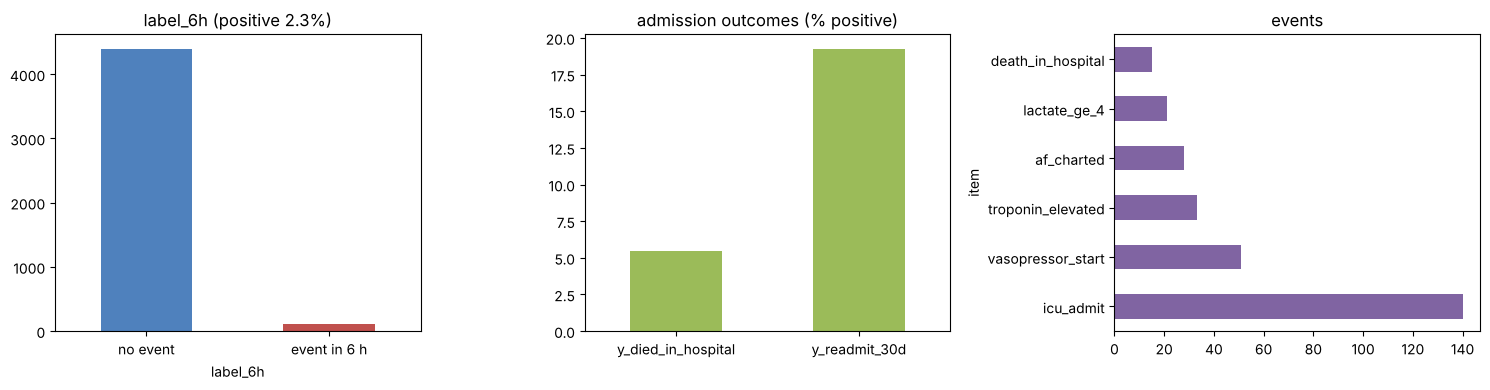

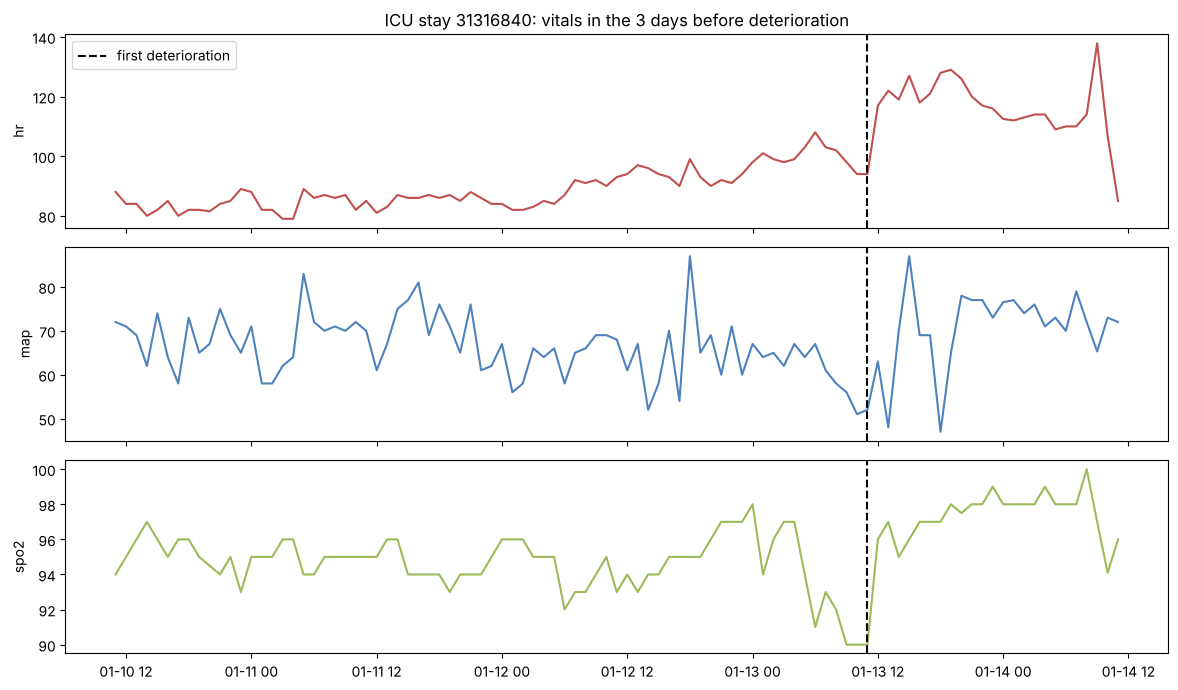

In [12]:
# class balance
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
model_table.label_6h.value_counts().sort_index().plot.bar(ax=axes[0], color=["#4f81bd", "#c0504d"])
axes[0].set_title(f"label_6h (positive {model_table.label_6h.mean():.1%})"); axes[0].set_xticklabels(["no event", "event in 6 h"], rotation=0)
static_clean[["y_died_in_hospital", "y_readmit_30d"]].mean().mul(100).plot.bar(ax=axes[1], color="#9bbb59")
axes[1].set_title("admission outcomes (% positive)"); axes[1].tick_params(axis="x", rotation=0)
cl[cl.source == "event"].item.value_counts().plot.barh(ax=axes[2], color="#8064a2"); axes[2].set_title("events")
savefig("04_class_balance")

# one patient's twin timeline
d = dynamic_clean.copy()
d["h_to_ev"] = (d.hadm_id.map(first_ev) - d.hour).dt.total_seconds() / 3600
sid = d[d.h_to_ev > 0].groupby("stay_id").h_to_ev.max().idxmax()
p = d[(d.stay_id == sid) & d.h_to_ev.between(-24, 72)]
fig, ax = plt.subplots(3, 1, figsize=(12, 7), sharex=True)
for a, (col, colr) in zip(ax, [("hr", "#c0504d"), ("map", "#4f81bd"), ("spo2", "#9bbb59")]):
    a.plot(p.hour, p[col], color=colr); a.set_ylabel(col)
    a.axvline(p.hour[p.h_to_ev <= 0].min(), color="k", ls="--", label="first deterioration")
ax[0].legend(); ax[0].set_title(f"ICU stay {sid}: vitals in the 3 days before deterioration")
savefig("05_patient_timeline")

**Result:** saved `figures/04_class_balance.png` and `figures/05_patient_timeline.png`. In the timeline, heart rate climbs from about 85 to 105, MAP falls from about 70 to 50 and SpO2 drops to 90% in the 1-2 days before the event. That's the early-warning pattern the twin learns, and it makes a good demo slide.

# STEP 4 · Extra datasets (different patients) and the cleaning report

**What this cell does:** cleans the two datasets from **different patients** (not merged with the 100 MIMIC patients):
- **Wearable:** removes the 2 empty columns, renames cuff BP to `sbp/dbp/map` so it matches the ICU vitals (for the live demo), applies the same range cleaning and forward-fills up to 30 min.
- **I-CARE:** encodes sex, adds `_missing` flags, fills ROSC with the median, and marks unknown values as -1/0.

It then writes `cleaning_report.json` and lists every file saved.

In [13]:
w = raw["wearable_5min"].drop(columns=["stay_id", "temp_c"]).rename(columns={"nbp_sys": "sbp", "nbp_dia": "dbp", "nbp_mean": "map"})
w["sbp"], w["dbp"], w["map"] = w.sbp.fillna(w.abp_sys), w.dbp.fillna(w.abp_dia), w["map"].fillna(w.abp_mean)
for col, (lo, hi) in RANGES.items():
    if col in w:
        w.loc[w[col].notna() & ~w[col].between(lo, hi), col] = np.nan
w = w.sort_values(["record_id", "time"])
for col in ["hr", "spo2", "rr", "sbp", "dbp", "map"]:
    w[col] = w.groupby("record_id")[col].ffill(limit=6)
save(w.reset_index(drop=True), CLEAN, "wearable_clean")

ic = raw["icare_patients"].copy()
ic["sex_male"] = ic.sex.map({"Male": 1, "Female": 0})
for col in ["rosc", "ohca", "shockable_rhythm", "ttm"]:
    ic[f"{col}_missing"] = ic[col].isna().astype(int)
ic["rosc"] = ic.rosc.fillna(ic.rosc.median())
ic[["ohca", "shockable_rhythm"]] = ic[["ohca", "shockable_rhythm"]].fillna(-1)
ic["ttm"] = ic.ttm.fillna(0)
save(ic.drop(columns=["sex", "outcome", "cpc"]), CLEAN, "icare_clean")

(CLEAN / "cleaning_report.json").write_text(json.dumps(report, indent=2, default=str))
for k, val in report.items():
    print(f"{k}: {val}")
print("\nmerged/ :", sorted(p.name for p in MERGED.glob("*.csv")))
print("cleaned/:", sorted(p.name for p in CLEAN.glob("*.csv")))
print("figures/:", sorted(p.name for p in FIG.glob("*.png")))

saved cleaned/wearable_clean         895 rows x 20 cols
saved cleaned/icare_clean            166 rows x 13 cols
saved: {'merged/static_merged': [275, 60], 'merged/clinical_merged': [52229, 11], 'merged/dynamic_merged': [12101, 15], 'cleaned/static_clean': [275, 63], 'cleaned/clinical_clean': [52171, 12], 'cleaned/dynamic_clean': [12015, 32], 'cleaned/model_table': [4503, 100], 'cleaned/wearable_clean': [895, 20], 'cleaned/icare_clean': [166, 13]}
static_imputed: {'bmi': 45, 'height_in': 49, 'weight_lbs': 37, 'sbp_outpatient': 51, 'dbp_outpatient': 51}
risk_factor_patients: {'smoker': 48, 'fam_hx_cad': 8, 'hyperlipidemia': 51, 'obesity': 20, 'prior_mi_or_revasc': 16, 'cad_history': 41}
clinical: {'rows_in': 52229, 'duplicates_removed': 36, 'ecg_studies_dropped': 1, 'negative_lab_values_set_nan': 0}
dynamic: {'pre_icu_hours_dropped': 86, 'temp_fahrenheit_fixed': 3, 'impossible_set_nan': {'hr': 1, 'spo2': 2, 'rr': 17, 'sbp': 3, 'dbp': 7, 'map': 41, 'temp_c': 0, 'gcs_total': 0}}
post_event

**Result:** `cleaned/wearable_clean.csv` (895 × 20) and `cleaned/icare_clean.csv` (166 × 13) saved. The folder now holds 3 merged CSVs, 6 cleaned CSVs (each with a `.pkl`), the report and 5 PNG charts so far. Step 5 below adds the model-ready files.

# STEP 5 · Preprocessing for the model and the live twin

**What this cell does (feature engineering):**
1. Writes the feature code to **`Happiest_Health/twin_preprocess.py`**, so training and the live twin use exactly the same code.
2. Adds new features to the model table for HR, MAP, SpO2, RR, SBP, NEWS score and shock index:
   - `_mean6h`, `_min6h`, `_max6h`: 6-hour rolling mean, min and max
   - `_delta6h`: change over 6 hours
   - `_lag1`: the previous hour's value
   - `_vs_baseline`: difference from **the patient's own normal so far** (expanding median). This is what makes it a twin: a heart rate of 100 means something different for a patient whose normal is 60.
3. Adds `lab_chg_<lab>`: the **change since the previous result** of each lab (for example, rising lactate or troponin).

Every feature only looks backward in time, so there is no leakage from the future. `hours_since_icu_admit` was already in the table.

In [14]:
# 5a. Write the feature functions to twin_preprocess.py, so training and the live twin use the SAME code
MODULE = '''
# Feature functions shared by the training notebook (02_merge_and_clean) and the live digital twin.
# Every function only looks BACKWARD in time, so the same code works on a live stream, hour by hour.
import numpy as np
import pandas as pd

RANGES = {"hr": (20, 250), "spo2": (50, 100), "rr": (4, 60), "sbp": (50, 250),
          "dbp": (20, 150), "map": (30, 200), "temp_c": (30, 43), "gcs_total": (3, 15)}
FFILL_LIMIT = {"hr": 4, "spo2": 4, "rr": 4, "sbp": 4, "dbp": 4, "map": 4, "temp_c": 8, "gcs_total": 8}
RHYTHMS = ["af_flutter", "brady", "other", "paced", "sinus", "tachy", "unknown"]
TREND_COLS = ["hr", "map", "spo2", "rr", "sbp", "news_score", "shock_index"]


def clean_vitals(v):
    # raw hourly vitals (one or more ICU stays) -> cleaned, same rules as step 2c
    v = v[v.hours_since_icu_admit >= 0].copy()
    f = v.temp_c.between(86, 110)
    v.loc[f, "temp_c"] = (v.loc[f, "temp_c"] - 32) * 5 / 9
    for col, (lo, hi) in RANGES.items():
        v.loc[v[col].notna() & ~v[col].between(lo, hi), col] = np.nan
    v = v.sort_values(["stay_id", "hour"])
    for col, lim in FFILL_LIMIT.items():
        v[f"{col}_measured"] = v[col].notna().astype(int)
        v[col] = v.groupby("stay_id")[col].ffill(limit=lim)
    v["arterial_line"] = (v.groupby("stay_id").bp_source.ffill() == "arterial").astype(int)
    return v


def _band(x, cuts, pts):
    return np.select([x <= c for c in cuts], pts[:-1], pts[-1]).astype(float)


def add_scores(v):
    # shock index and NEWS2 (without the oxygen-therapy item)
    v = v.copy()
    v["shock_index"] = (v.hr / v.sbp).round(3)
    news = pd.DataFrame({
        "rr": _band(v.rr, [8, 11, 20, 24], [3, 1, 0, 2, 3]),
        "spo2": _band(v.spo2, [91, 93, 95], [3, 2, 1, 0]),
        "sbp": np.where(v.sbp >= 220, 3, _band(v.sbp, [90, 100, 110], [3, 2, 1, 0])),
        "hr": _band(v.hr, [40, 50, 90, 110, 130], [3, 1, 0, 1, 2, 3]),
        "temp": _band(v.temp_c, [35, 36, 38, 39], [3, 1, 0, 1, 2]),
        "gcs": np.where(v.gcs_total < 15, 3, 0)}, index=v.index)
    for col, src in [("rr", "rr"), ("spo2", "spo2"), ("sbp", "sbp"), ("hr", "hr"), ("temp", "temp_c"), ("gcs", "gcs_total")]:
        news.loc[v[src].isna(), col] = 0
    v["news_score"] = news.sum(axis=1).astype(int)
    return v


def rhythm_group(r):
    if pd.isna(r):
        return "unknown"
    r = r.strip().lower()
    return ("af_flutter" if r.startswith(("af ", "a flut")) else "paced" if "paced" in r else
            "tachy" if r.startswith(("st ", "svt", "pat", "vt ")) else "brady" if r.startswith(("sb ", "jr ")) else
            "sinus" if r.startswith(("sr ", "sa ", "1st av")) else "other")


def one_hot_rhythm(v):
    v = v.copy()
    g = v.rhythm.map(rhythm_group)
    for r in RHYTHMS:
        v[f"rhythm_{r}"] = (g == r).astype(int)
    return v.drop(columns=["rhythm", "bp_source"])


def add_time_features(t):
    # per ICU stay, using only the current and earlier hours
    t = t.sort_values(["stay_id", "hour"]).copy()
    for col in TREND_COLS:
        g = t.groupby("stay_id")[col]
        t[f"{col}_mean6h"] = g.transform(lambda x: x.rolling(6, min_periods=1).mean())
        t[f"{col}_min6h"] = g.transform(lambda x: x.rolling(6, min_periods=1).min())
        t[f"{col}_max6h"] = g.transform(lambda x: x.rolling(6, min_periods=1).max())
        t[f"{col}_delta6h"] = t[col] - g.shift(6)
        t[f"{col}_lag1"] = g.shift(1)
        t[f"{col}_vs_baseline"] = t[col] - g.transform(lambda x: x.expanding().median())   # vs the patient's own normal so far
    return t


def add_labs(t, lab, tolerance_h, log_labs=(), value=True, change=True):
    # lab: long table with hadm_id, time, item, v. Adds the latest value and the change since the previous result.
    lab = lab.sort_values("time").copy()
    lab["chg"] = lab.groupby(["hadm_id", "item"]).v.diff()
    t = t.sort_values("hour")
    for name, tol in tolerance_h.items():
        cols = {"time": "hour"}
        if value:
            cols["v"] = f"lab_log_{name}" if name in log_labs else f"lab_{name}"
        if change:
            cols["chg"] = f"lab_chg_{name}"
        l = lab[lab.item == name][["hadm_id"] + list(cols)].rename(columns=cols).sort_values("hour")
        t = pd.merge_asof(t, l, on="hour", by="hadm_id", direction="backward", tolerance=pd.Timedelta(hours=tol))
    return t


def build_features(vitals_raw, static_feats, labs=None, lab_tolerance_h=None, log_labs=(), extra=None):
    # one ICU stay: raw hourly vitals + static values (from the record or entered by the user) -> model features
    v = add_time_features(add_scores(one_hot_rhythm(clean_vitals(vitals_raw))))
    for k, val in static_feats.items():
        v[k] = val
    if labs is not None:
        v = add_labs(v, labs, lab_tolerance_h, log_labs)
    if extra is not None:
        v = v.merge(extra, on="hour", how="left")
    return v.sort_values("hour").reset_index(drop=True)


def to_matrix(t, config, scaled=False):
    # same columns, same order as training; optional scaling with the TRAIN mean/std
    X = t.reindex(columns=config["features"]).astype(float)
    if scaled:
        for col, (mu, sd) in config["scaler"].items():
            X[col] = (X[col] - mu) / sd
        X = X.fillna(0)
    return X
'''
PIPE = DATA.parent / "src" / "twin_preprocess.py"
PIPE.write_text(MODULE.lstrip())
import importlib, sys
sys.path.insert(0, str(PIPE.resolve().parent))
import twin_preprocess as tp
importlib.reload(tp)

# 5b. More features on the model table
LAB_TOL = {n: 24 for n in COMMON} | {n: 72 for n in RARE}
mt = tp.add_time_features(model_table)
mt = tp.add_labs(mt, lab, LAB_TOL, value=False)
mt = mt.sort_values(["stay_id", "hour"]).reset_index(drop=True)
new_cols = [c for c in mt.columns if c not in model_table.columns]
print(f"model table {model_table.shape} -> {mt.shape}: {len(new_cols)} new features")
print("examples:", new_cols[:6], "...", new_cols[-3:])
print("saved", PIPE.resolve())

model table (4503, 100) -> (4503, 160): 60 new features
examples: ['hr_mean6h', 'hr_min6h', 'hr_max6h', 'hr_delta6h', 'hr_lag1', 'hr_vs_baseline'] ... ['lab_chg_ntprobnp', 'lab_chg_ck', 'lab_chg_ck_mb']
saved /tmp/claude-0/run/Happiest_Health/twin_preprocess.py


**Result:** model table grows from 100 to **160 columns (60 new features)**. `twin_preprocess.py` is saved next to this notebook.

**What this cell does (train/test split):** splits by **patient**, never by row, so the same patient is never in both train and test. 20% of patients go to the test set, stratified so patients with and without events are spread evenly. The training patients are further split into **5 cross-validation folds** (`cv_fold` 0 to 4; the test set is -1). This happens **before** anything is fitted, so feature selection and scaling only learn from train.

In [15]:
# 5c. Train/test split BY PATIENT (before anything is fitted)
rng = np.random.default_rng(42)
patient_has_event = mt.groupby("subject_id").label_6h.max()
test_ids, fold_of = [], {}
for has_event, ids in patient_has_event.groupby(patient_has_event):      # stratified: patients with and without events
    ids = rng.permutation(ids.index.values)
    n_test = int(round(len(ids) * 0.2))
    test_ids += list(ids[:n_test])
    for k, sid in enumerate(ids[n_test:]):
        fold_of[sid] = k % 5                                             # 5 cross-validation folds inside train
mt["split"] = np.where(mt.subject_id.isin(test_ids), "test", "train")
mt["cv_fold"] = mt.subject_id.map(fold_of).fillna(-1).astype(int)
assert not set(mt[mt.split == "test"].subject_id) & set(mt[mt.split == "train"].subject_id)
split_summary = mt.groupby("split").agg(patients=("subject_id", "nunique"), hours=("hour", "size"),
                                        positives=("label_6h", "sum"), positive_rate=("label_6h", "mean")).round(3)
print(split_summary)
print(mt[mt.split == "train"].groupby("cv_fold").agg(patients=("subject_id", "nunique"), positives=("label_6h", "sum")).T)

       patients  hours  positives  positive_rate
split                                           
test         17   1084         25          0.023
train        69   3419         78          0.023
cv_fold     0   1   2   3   4
patients   15  14  14  13  13
positives  25  17  14  14   8


**Result:** **train 69 patients / 3,419 hours / 78 positives**, **test 17 patients / 1,084 hours / 25 positives**. Both have the same 2.3% positive rate. Each CV fold has 13 to 15 patients and 8 to 25 positive hours. No patient is in both sets (checked by `assert`).

**What this cell does (feature selection, on train rows only):**
1. Drops **near-constant** columns (one value in 99.5% or more of rows), since they carry almost no information.
2. For each pair of columns with **correlation above 0.95** (measured together in at least 300 hours), drops the later one and keeps the first.

The risk factors (smoking, CAD history, family history, and so on) plus NEWS and shock index are protected and always kept.

In [16]:
# 5d. Feature selection (decided on the TRAIN rows only)
ID_COLS = ["subject_id", "hadm_id", "stay_id", "hour", "split", "cv_fold", "label_6h", "label_12h"]
KEEP = ["smoker", "fam_hx_cad", "hyperlipidemia", "obesity", "prior_mi_or_revasc", "cad_history", "news_score", "shock_index"]
candidates = [c for c in mt.columns if c not in ID_COLS]
tr = mt[mt.split == "train"]
top_share = {c: tr[c].value_counts(normalize=True, dropna=False).iloc[0] for c in candidates}
near_constant = [c for c in candidates if top_share[c] >= 0.995 and not (c in KEEP and tr[c].nunique() > 1)]
rest = [c for c in candidates if c not in near_constant]
corr = tr[rest].corr(min_periods=300).abs()                         # pairs measured together in at least 300 hours
too_correlated, kept = {}, []
for c in rest:
    twin = next((k for k in kept if corr.loc[c, k] > 0.95), None)
    if twin is not None and c not in KEEP:
        too_correlated[c] = twin
    else:
        kept.append(c)
FEATURES = kept
print(f"{len(candidates)} candidate features -> {len(FEATURES)} kept")
print("near-constant (dropped):", near_constant)
print("highly correlated (dropped -> kept twin):", too_correlated)

154 candidate features -> 146 kept
near-constant (dropped): ['rhythm_other', 'hist_arrest', 'lab_chg_ntprobnp']
highly correlated (dropped -> kept twin): {'dbp_measured': 'sbp_measured', 'map_measured': 'sbp_measured', 'log_rmssd_ms': 'log_sdnn_ms', 'hr_min6h': 'hr_mean6h', 'shock_index_min6h': 'shock_index_mean6h'}


**Result:** **154 candidates, 146 kept.** Near-constant and dropped: `rhythm_other`, `hist_arrest` (no train patient had a prior arrest), `lab_chg_ntprobnp`. Highly correlated and dropped: `dbp_measured` and `map_measured` (same as `sbp_measured`), `log_rmssd_ms` (same as `log_sdnn_ms`), `hr_min6h` and `shock_index_min6h` (same as their 6 h mean).

**What this cell does (scaling and class imbalance), then saves:**
- **Scaling:** standardizes continuous features with the **train** mean and std (z-score); 0/1 flags are left alone. Missing values become 0 (the train mean) in the scaled file. This is only for logistic regression or a neural network/LSTM. **XGBoost uses the unscaled `model_ready.csv`**, where it handles missing values itself.
- **Imbalance:** `scale_pos_weight` = negative hours ÷ positive hours in train, which tells XGBoost to weight each rare event hour more. No SMOTE.
- Saves `model_ready.csv`, `model_ready_scaled.csv` and **`preprocess_config.json`** (feature list and order, scaler values, class weight, dropped columns, test patients, lab settings). The live twin reads this config.

In [17]:
# 5e. Scaling (train mean/std, only for logistic regression / neural nets) + class weights, then save
binary = [c for c in FEATURES if set(tr[c].dropna().unique()) <= {0, 1}]
continuous = [c for c in FEATURES if c not in binary]
scaler = {c: (float(tr[c].mean()), float(tr[c].std()) or 1.0) for c in continuous}
n_pos, n_neg = int(tr.label_6h.sum()), int((tr.label_6h == 0).sum())
config = {"label": "label_6h", "features": FEATURES, "binary": binary, "scaler": scaler,
          "scale_pos_weight": round(n_neg / n_pos, 2),
          "dropped_near_constant": near_constant, "dropped_correlated": too_correlated,
          "test_patients": sorted(int(i) for i in test_ids),
          "lab_tolerance_h": LAB_TOL, "log_labs": SKEWED}
model_ready = mt[ID_COLS + FEATURES]
scaled = pd.concat([mt[ID_COLS], tp.to_matrix(mt, config, scaled=True)], axis=1)
save(model_ready, CLEAN, "model_ready")
save(scaled, CLEAN, "model_ready_scaled")
(CLEAN / "preprocess_config.json").write_text(json.dumps(config, indent=1))
report["preprocessing"] = {"features": len(FEATURES), "binary": len(binary), "continuous": len(continuous),
                           "train_pos_neg": [n_pos, n_neg], "scale_pos_weight": config["scale_pos_weight"],
                           "split": split_summary.reset_index().to_dict("records")}
(CLEAN / "cleaning_report.json").write_text(json.dumps(report, indent=2, default=str))
print(len(FEATURES), "features:", len(binary), "binary (not scaled),", len(continuous), "continuous (scaled)")
print(f"train: {n_pos} positive / {n_neg} negative hours -> scale_pos_weight = {config['scale_pos_weight']}")

saved cleaned/model_ready          4,503 rows x 154 cols


saved cleaned/model_ready_scaled   4,503 rows x 154 cols
146 features: 48 binary (not scaled), 98 continuous (scaled)
train: 78 positive / 3341 negative hours -> scale_pos_weight = 42.83


**Result:** **146 features: 48 binary (not scaled), 98 continuous (scaled).** Train has 78 positive and 3,341 negative hours, so **`scale_pos_weight` = 42.83**. Saved `cleaned/model_ready.csv` and `cleaned/model_ready_scaled.csv` (4,503 × 154 each: 146 features plus ids, split, fold and labels) and `cleaned/preprocess_config.json`.

**What this cell does (reusable pipeline check):** takes one test-set ICU stay **straight from the raw `dynamic_merged.csv`** and runs it through `twin_preprocess.build_features()`. That covers cleaning, NEWS and shock index, rhythm one-hot, trends and labs. It then compares the result with the same hours in `model_ready.csv`. ECG and medication flags are passed in as they are, and static values come from the patient record (in the app, from the record plus user entries).

In [18]:
# 5f. Check the twin pipeline: raw hourly vitals of one TEST stay -> same features as model_ready
sid = mt[(mt.split == "test") & (mt.label_6h == 1)].stay_id.iloc[0]
rows = model_ready[model_ready.stay_id == sid].sort_values("hour")
raw_vitals = dynamic[dynamic.stay_id == sid]                                # straight from dynamic_merged.csv
hadm = int(rows.hadm_id.iloc[0])
ecg_med_cols = [c for c in FEATURES if c.startswith(("on_", "ecg_", "log_sdnn", "log_rmssd", "rr_cv", "pnn50", "r_amp", "hours_since_ecg", "has_ecg"))]
STATIC_COLS = [c for c in FEATURES if c not in ecg_med_cols and (c in static_clean.columns or c.startswith(("hist_", "admission_type_", "race_")))]
static_feats = rows[STATIC_COLS].iloc[0].to_dict()                           # in the app: patient record + user entries
live = tp.build_features(raw_vitals, static_feats, labs=lab[lab.hadm_id == hadm], lab_tolerance_h=LAB_TOL,
                         log_labs=SKEWED, extra=rows[["hour"] + ecg_med_cols])
live = live[live.hour.isin(rows.hour)]
X_live, X_train = tp.to_matrix(live, config), tp.to_matrix(rows, config)
same = np.isclose(X_live.values, X_train.values, equal_nan=True)
print(f"ICU stay {sid}: {len(rows)} hours x {len(FEATURES)} features rebuilt from raw vitals with twin_preprocess.py")
print(f"identical values: {same.mean():.2%}")

ICU stay 31316840: 227 hours x 146 features rebuilt from raw vitals with twin_preprocess.py
identical values: 100.00%


**Result:** ICU stay 31316840, 227 hours × 146 features: **100.00% identical**. The live twin can process each new hour exactly as in training with `tp.build_features(...)` followed by `tp.to_matrix(..., config)`.

**What this cell does:** charts the correlation of the main features (train rows) and checks the split.

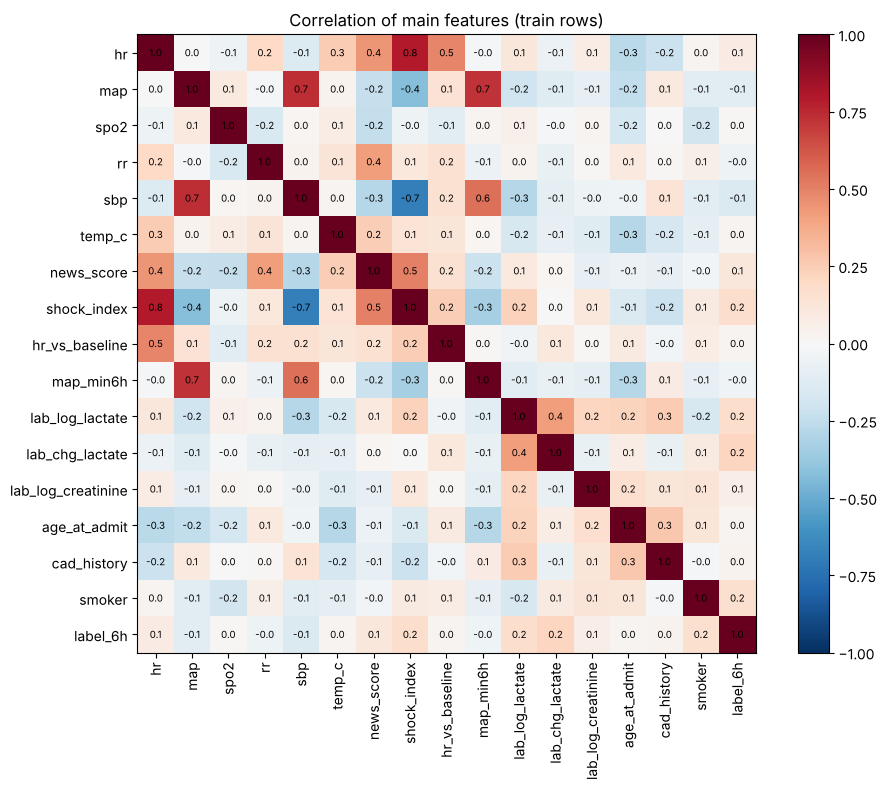

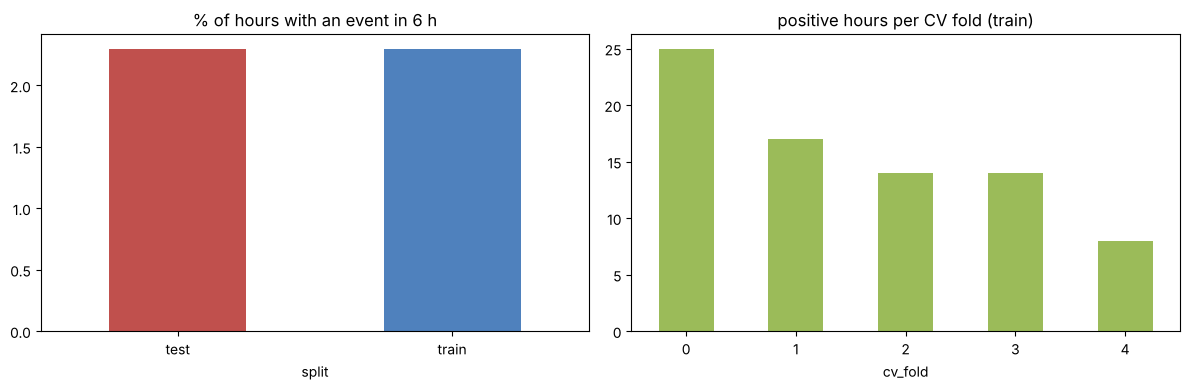

['clinical_clean.csv', 'dynamic_clean.csv', 'icare_clean.csv', 'model_ready.csv', 'model_ready_scaled.csv', 'model_table.csv', 'static_clean.csv', 'wearable_clean.csv']


In [19]:
# figures: correlation of the main kept features, and the split
main = [c for c in ["hr", "map", "spo2", "rr", "sbp", "temp_c", "news_score", "shock_index", "hr_vs_baseline",
                    "map_min6h", "lab_log_lactate", "lab_chg_lactate", "lab_log_creatinine",
                    "age_at_admit", "cad_history", "smoker", "label_6h"] if c in model_ready]
cm = model_ready[model_ready.split == "train"][main].corr()
fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(cm, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(main))); ax.set_xticklabels(main, rotation=90); ax.set_yticks(range(len(main))); ax.set_yticklabels(main)
for i in range(len(main)):
    for j in range(len(main)):
        ax.text(j, i, f"{cm.iloc[i, j]:.1f}", ha="center", va="center", fontsize=7)
fig.colorbar(im); ax.set_title("Correlation of main features (train rows)")
savefig("06_feature_correlation")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
split_summary.positive_rate.mul(100).plot.bar(ax=axes[0], color=["#c0504d", "#4f81bd"])
axes[0].set_title("% of hours with an event in 6 h"); axes[0].tick_params(axis="x", rotation=0)
mt[mt.split == "train"].groupby("cv_fold").label_6h.sum().plot.bar(ax=axes[1], color="#9bbb59")
axes[1].set_title("positive hours per CV fold (train)"); axes[1].tick_params(axis="x", rotation=0)
savefig("07_split_check")
print(sorted(p.name for p in CLEAN.glob("*.csv")))

**Result:** saved `figures/06_feature_correlation.png` and `figures/07_split_check.png`. Shock index, lactate, the change in lactate and smoking have the strongest link with `label_6h` (about 0.2 each). Single features are weak on their own, which is normal; the model combines them. Shock index tracks HR (0.8) and SBP (-0.7) as expected, but stays below the 0.95 cut, so both are kept. Test and train both have a 2.3% event rate.

## Next step
Train on `cleaned/model_ready.pkl`: features = `preprocess_config.json["features"]`, target `label_6h`. Use `split == "train"` with `cv_fold` for cross-validation, and keep `split == "test"` untouched until the end. XGBoost with `scale_pos_weight` from the config, scored on AUROC and AUPRC (not accuracy).